In [1]:
# Import the library to mount Google Drive
from google.colab import drive

In [2]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_name_patterns = "patterns_metadata_cleaned.csv"
file_path_patterns = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_patterns}"
data_path_patterns = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"

In [4]:
import pandas as pd

df = pd.read_csv(file_path_patterns)
print(len(df))          # number of rows


1000


In [6]:
rows, cols = df.shape
print(rows, cols)


1000 6


In [16]:
import pandas as pd

df = pd.read_csv(file_path_patterns)
print(df.head(20))


                            structure_id  extinction_group  space_group  \
0   01f4250a-125f-44c5-815a-c20fafc49ea7                73          159   
1   c39d7883-927b-470f-8035-34ee71681b8a                73          159   
2   242e85e7-6ade-4c94-8a0c-234f462262d0                73          159   
3   0483610e-9bd7-4b13-8e3c-1dad8d8b7d35                73          159   
4   6c0a611e-bdac-4d15-9936-e19cbc109480                73          159   
5   0bcd11a2-9029-4669-abdd-7297f9888c48                74          158   
6   be446a77-7379-4e15-8afb-4edcd48da34c                74          158   
7   4564f6a8-407f-455c-81d1-0383893499f8                74          158   
8   73bafac3-adad-4b25-aaa7-35e21044e14c                74          158   
9   dd417466-a6fb-4972-90ec-f2f3279b839e                74          158   
10  a8922d80-0b66-44f2-8009-fe4c81d0210c                74          158   
11  4347d32e-834b-4616-90b4-54c1df9ac4b1                74          158   
12  bde8173b-15a8-4766-ba

In [7]:
file_name_RRUFF_interp = "RRUFF_interp_data.hdf5"
file_path_RRUFF_interp = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_RRUFF_interp}"
data_path_RRUFF_interp = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"

In [18]:
file_path_RRUFF_interp

'/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_interp_data.hdf5'

In [19]:
import h5py

with h5py.File(file_path_RRUFF_interp, "r") as f:
    def print_tree(name, obj):
        print(name, obj)

    f.visititems(print_tree)


2theta <HDF5 dataset "2theta": shape (8501,), type "<f4">
composition <HDF5 dataset "composition": shape (1000,), type "|O">
extinction_group <HDF5 dataset "extinction_group": shape (1000,), type "<i4">
intensity <HDF5 dataset "intensity": shape (1000, 8501), type "<f4">
source <HDF5 dataset "source": shape (1000,), type "|O">
space_group <HDF5 dataset "space_group": shape (1000,), type "<i4">
structure_id <HDF5 dataset "structure_id": shape (1000,), type "|O">


In [ ]:
import h5py
import numpy as np

def summarize_dataset(name, dset):
    print(f"\n=== {name} ===")
    print("Shape:", dset.shape)
    print("Dtype:", dset.dtype)

    # Numeric datasets
    if np.issubdtype(dset.dtype, np.number):
        data = dset[()]  # safe for your sizes
        print("Min:", np.nanmin(data))
        print("Max:", np.nanmax(data))
        print("Mean:", np.nanmean(data))
        print("Std:", np.nanstd(data))
        print("NaNs:", np.isnan(data).sum())

    # Object / string datasets
    else:
        data = dset[:]
        uniques = np.unique(data)
        print("Unique values:", len(uniques))
        print("Example values:", uniques[:5])


with h5py.File(file_path_RRUFF_interp, "r") as f:
    for key in f.keys():
        summarize_dataset(key, f[key])



=== 2theta ===
Shape: (8501,)
Dtype: float32
Min: 5.0
Max: 90.0
Mean: 47.5
Std: 24.540272
NaNs: 0

=== composition ===
Shape: (1000,)
Dtype: object
Unique values: 999
Example values: [b'Ac12Ba4Mn6' b'Ac16Pt2' b'Ac2Os16' b'Ac32Cs48' b'Ac4Er16Sr2']

=== extinction_group ===
Shape: (1000,)
Dtype: int32
Min: 1
Max: 99
Mean: 49.722
Std: 28.82579948587723
NaNs: 0

=== intensity ===
Shape: (1000, 8501)
Dtype: float32
Min: 0.0
Max: 1000.0
Mean: 10.785782
Std: 55.5964
NaNs: 0

=== source ===
Shape: (1000,)
Dtype: object
Unique values: 1
Example values: [b'PyXtal']

=== space_group ===
Shape: (1000,)
Dtype: int32
Min: 1
Max: 230
Mean: 105.865
Std: 68.08257321077106
NaNs: 0

=== structure_id ===
Shape: (1000,)
Dtype: object
Unique values: 1000
Example values: [b'005230b1-0cf9-473c-bbd3-57f43b43784d'
 b'00525649-ea7e-4eb2-a2a7-30018624cedc'
 b'00698289-1867-49f5-8199-3bcdcb844fec'
 b'007055fc-2bad-4bed-a053-7aa61f61217d'
 b'00b735a9-c1f9-4268-9b7a-734304ee5e62']


In [ ]:
import h5py
import numpy as np

def print_first_20(name, dset):
    print(f"\n=== {name} ===")
    print("Shape:", dset.shape)
    print("Dtype:", dset.dtype)

    # 2D datasets (e.g., intensity)
    if dset.ndim == 2:
        print("First 20 rows, first 20 columns:")
        print(dset[:20, :20])

    # 1D datasets
    else:
        data = dset[:20]
        print("First 20 values:")
        print(data)


with h5py.File(file_path_RRUFF_interp, "r") as f:
    for key in f.keys():
        print_first_20(key, f[key])



=== 2theta ===
Shape: (8501,)
Dtype: float32
First 20 values:
[5.   5.01 5.02 5.03 5.04 5.05 5.06 5.07 5.08 5.09 5.1  5.11 5.12 5.13
 5.14 5.15 5.16 5.17 5.18 5.19]

=== composition ===
Shape: (1000,)
Dtype: object
First 20 values:
[b'C6Pa6' b'Hg6Nd2' b'Ag6O2Ti2' b'B2Ni6' b'Li6Po6Re2' b'Ni2W6' b'Ra2Zr6'
 b'Ga6Po6' b'Cr6In2Sb6' b'Lu6O2' b'Cs6Sc6' b'B6Sn6' b'Kr6Ta6' b'Au2Tc6'
 b'Cd6Si2' b'Nd9Pt9' b'Ra9Yb3' b'Ca3Ne9V9' b'Hg9Li9Ru9' b'Ra3Rh9']

=== extinction_group ===
Shape: (1000,)
Dtype: int32
First 20 values:
[73 73 73 73 73 74 74 74 74 74 74 74 74 74 74 75 75 75 75 75]

=== intensity ===
Shape: (1000, 8501)
Dtype: float32
First 20 rows, first 20 columns:
[[0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 0.

In [20]:
file_name_db = "intrep_crystal_xrd.db"
file_path_db = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_db}"
data_path_db = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"

In [21]:
import sqlite3

db_path = file_path_db

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Example: list tables (optional)
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print("Tables:", cursor.fetchall())

# Query first 10 rows from a table
cursor.execute("""
    SELECT *
    FROM Structures
    LIMIT 10;
""")

rows = cursor.fetchall()
for row in rows:
    print(row)

conn.close()


Tables: [('Structures',)]
('331be1ef-d48c-41e1-8479-451d0912be8c', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 1, 'Monoclinic', 6, 'Ir2Sc2Yb2', 6.2824886330621945, 4.79225379515856, 5.521027253930496, 90.0, 100.75613636611877, 90.0, "[{'symbol': 'Sc', 'position': array([0.92383867, 0.24375713, 0.65795994])}, {'symbol': 'Sc', 'position': array([0.92383867, 0.75624287, 0.65795994])}, {'symbol': 'Yb', 'position': array([0.3819144 , 0.        , 0.71845362])}, {'symbol': 'Yb', 'position': array([9.72797476e-02, 8.15776052e-34, 5.88539094e-02])}, {'symbol': 'Ir', 'position': array([0.52261759, 0.5       , 0.2992619 ])}, {'symbol': 'Ir', 'position': array([1.07664725e-01, 2.46901921e-33, 3.84604954e-01])}]")
('dba1436a-8f3b-4e50-af7a-93ad2fad9ca3', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 1, 'Monoclinic', 6, 'Ar2Mg2', 5.990829914336133, 2.9561457994054594, 5.99176592874995, 90.0, 68.08912934779003, 90.0, "[{'symbol': 'Mg', 'position': array([0.70888292, 0.5       , 0.67

In [ ]:
import sqlite3

db_path = file_path_db

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# List tables
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()
print("Tables:", tables)

# Query first 10 rows from 'Structures' table
cursor.execute("SELECT * FROM Structures LIMIT 10;")
rows = cursor.fetchall()

# Get column names
column_names = [description[0] for description in cursor.description]
print("Columns:", column_names)

# Print rows
for row in rows:
    print(row)

conn.close()


Tables: [('Structures',)]
Columns: ['structure_id', 'source', 'generation_commit', 'extinction_group', 'crystal_system', 'space_group', 'composition', 'lattice_a', 'lattice_b', 'lattice_c', 'alpha', 'beta', 'gamma', 'atom_sites_json']
('331be1ef-d48c-41e1-8479-451d0912be8c', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 1, 'Monoclinic', 6, 'Ir2Sc2Yb2', 6.2824886330621945, 4.79225379515856, 5.521027253930496, 90.0, 100.75613636611877, 90.0, "[{'symbol': 'Sc', 'position': array([0.92383867, 0.24375713, 0.65795994])}, {'symbol': 'Sc', 'position': array([0.92383867, 0.75624287, 0.65795994])}, {'symbol': 'Yb', 'position': array([0.3819144 , 0.        , 0.71845362])}, {'symbol': 'Yb', 'position': array([9.72797476e-02, 8.15776052e-34, 5.88539094e-02])}, {'symbol': 'Ir', 'position': array([0.52261759, 0.5       , 0.2992619 ])}, {'symbol': 'Ir', 'position': array([1.07664725e-01, 2.46901921e-33, 3.84604954e-01])}]")
('dba1436a-8f3b-4e50-af7a-93ad2fad9ca3', 'PyXtal', '3e5b6cb27ee263b875

In [22]:
import sqlite3

db_path = file_path_db

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Query first 10 rows from a table
cursor.execute("""
    SELECT *
    FROM Structures
    WHERE crystal_system = 'Monoclinic'
    LIMIT 10;
""")

rows = cursor.fetchall()
for row in rows:
    print(row)

conn.close()

('331be1ef-d48c-41e1-8479-451d0912be8c', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 1, 'Monoclinic', 6, 'Ir2Sc2Yb2', 6.2824886330621945, 4.79225379515856, 5.521027253930496, 90.0, 100.75613636611877, 90.0, "[{'symbol': 'Sc', 'position': array([0.92383867, 0.24375713, 0.65795994])}, {'symbol': 'Sc', 'position': array([0.92383867, 0.75624287, 0.65795994])}, {'symbol': 'Yb', 'position': array([0.3819144 , 0.        , 0.71845362])}, {'symbol': 'Yb', 'position': array([9.72797476e-02, 8.15776052e-34, 5.88539094e-02])}, {'symbol': 'Ir', 'position': array([0.52261759, 0.5       , 0.2992619 ])}, {'symbol': 'Ir', 'position': array([1.07664725e-01, 2.46901921e-33, 3.84604954e-01])}]")
('dba1436a-8f3b-4e50-af7a-93ad2fad9ca3', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 1, 'Monoclinic', 6, 'Ar2Mg2', 5.990829914336133, 2.9561457994054594, 5.99176592874995, 90.0, 68.08912934779003, 90.0, "[{'symbol': 'Mg', 'position': array([0.70888292, 0.5       , 0.67045884])}, {'symbol': 'Mg'

Monoclinic
331be1ef-d48c-41e1-8479-451d0912be8c

In [23]:
import sqlite3

db_path = file_path_db

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Query first 10 rows from a table
cursor.execute("""
    SELECT *
    FROM Structures
    WHERE crystal_system = 'Cubic'
    LIMIT 10;
""")

rows = cursor.fetchall()
for row in rows:
    print(row)

conn.close()

('b8a70760-d7b9-49d9-93bf-74696d8978c3', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 81, 'Cubic', 207, 'B9Er36V3', 11.572191985720128, 11.572191985720128, 11.572191985720128, 90.0, 90.0, 90.0, "[{'symbol': 'B', 'position': array([0.37655982, 0.37655982, 0.37655982])}, {'symbol': 'B', 'position': array([0.62344018, 0.62344018, 0.37655982])}, {'symbol': 'B', 'position': array([0.62344018, 0.37655982, 0.62344018])}, {'symbol': 'B', 'position': array([0.37655982, 0.62344018, 0.62344018])}, {'symbol': 'B', 'position': array([0.37655982, 0.37655982, 0.62344018])}, {'symbol': 'B', 'position': array([0.62344018, 0.62344018, 0.62344018])}, {'symbol': 'B', 'position': array([0.37655982, 0.62344018, 0.37655982])}, {'symbol': 'B', 'position': array([0.62344018, 0.37655982, 0.37655982])}, {'symbol': 'B', 'position': array([0., 0., 0.])}, {'symbol': 'V', 'position': array([0. , 0. , 0.5])}, {'symbol': 'V', 'position': array([5.00000000e-01, 1.40192587e-32, 1.27816251e-32])}, {'symbol': 'V'

Cubic
b8a70760-d7b9-49d9-93bf-74696d8978c3

In [24]:
import sqlite3

db_path = file_path_db

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Query first 10 rows from a table
cursor.execute("""
    SELECT *
    FROM Structures
    WHERE crystal_system = 'Orthorhombic'
    LIMIT 10;
""")

rows = cursor.fetchall()
for row in rows:
    print(row)

conn.close()

('b41d0516-a5fd-4785-adc2-5b5257048df9', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 7, 'Orthorhombic', 25, 'Ho2Ti2', 4.1452399577988395, 5.501697793870185, 5.187452317834676, 90.0, 90.0, 90.0, "[{'symbol': 'Ti', 'position': array([0.        , 0.        , 0.64227006])}, {'symbol': 'Ti', 'position': array([0.5       , 0.5       , 0.32358813])}, {'symbol': 'Ho', 'position': array([0.       , 0.5      , 0.4588281])}, {'symbol': 'Ho', 'position': array([0.5       , 0.        , 0.98312578])}]")
('0f075659-0f1e-482a-b4a1-caf0b365b4da', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 7, 'Orthorhombic', 25, 'Ba2Ne4', 7.79353252483268, 6.010063461286228, 5.073453894273446, 90.0, 90.0, 90.0, "[{'symbol': 'Ne', 'position': array([0.86949843, 0.39865163, 0.06194435])}, {'symbol': 'Ne', 'position': array([0.13050157, 0.60134837, 0.06194435])}, {'symbol': 'Ne', 'position': array([0.86949843, 0.60134837, 0.06194435])}, {'symbol': 'Ne', 'position': array([0.13050157, 0.39865163, 0.0619

Orthorhombic
b41d0516-a5fd-4785-adc2-5b5257048df9

In [5]:
import h5py
import numpy as np

def find_indices_by_structure_id(
    hdf5_path,
    target_structure_id,
    structure_id_key="structure_id",
):
    """
    Search HDF5 dataset for matching structure_id(s).

    Parameters
    ----------
    hdf5_path : str
        Path to HDF5 file
    target_structure_id : str | int | list[str|int]
        Structure ID(s) to search for
    structure_id_key : str
        Dataset name containing structure IDs

    Returns
    -------
    dict
        {structure_id: np.ndarray(indices)}
    """

    # Normalize targets
    if isinstance(target_structure_id, (list, tuple, set)):
        targets = set(str(t) for t in target_structure_id)
    else:
        targets = {str(target_structure_id)}

    matches = {t: [] for t in targets}

    with h5py.File(hdf5_path, "r") as f:
        if structure_id_key not in f:
            raise KeyError(f"'{structure_id_key}' not found in HDF5 file")

        sids = f[structure_id_key][:]

        for idx, sid in enumerate(sids):
            # Decode bytes if needed
            if isinstance(sid, (bytes, np.bytes_)):
                sid = sid.decode("utf-8")

            sid_str = str(sid)

            if sid_str in matches:
                matches[sid_str].append(idx)

    # Convert lists → arrays
    return {k: np.array(v, dtype=int) for k, v in matches.items()}


In [11]:
indices = find_indices_by_structure_id(
    file_path_RRUFF_interp,
    target_structure_id="331be1ef-d48c-41e1-8479-451d0912be8c"
)

print(indices)
# {'1507754': array([12, 847, 2194])}


{'331be1ef-d48c-41e1-8479-451d0912be8c': array([25])}


**0-based index of crystal systems of interest**

Orthorhombic: 85

Cubic: 275

Monoclinic: 25

In [ ]:
!pip install pymatgen

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.9/51.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 809.1/809.1 kB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.2/788.2 kB 32.4 MB/s eta 0:00:00
  Created wheel for bibtexparser: filename=bibtexparser-1.4.3-py3-none-any.whl size=43549 sha256=4816f9c3ad3dd83866135f6b592c49383c9dba3db4819fe0a02dc3d6df04c08b
  Stored in directory: /root/.cache/pip/wheels/1f/7d/e9/1ff2509f13767a55df1279744adfb757f4ab94b2cbe761f56a
Successfully built bibtexparser


In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pymatgen.core import Lattice

def plot_xrd_measured_with_hkls_lattice(hdf5_path, db_path, pattern_index,
                                        wavelength=1.541838,
                                        twotheta_min=5, twotheta_max=90,
                                        max_hkl_index=5):
    """
    Plot measured XRD from HDF5 and overlay allowed (hkl) positions
    using lattice parameters from SQLite DB.
    Uses pymatgen.Lattice.d_hkl() for universal crystal system support.
    """
    # --- 1) Load measured pattern ---
    with h5py.File(hdf5_path, "r") as f:
        two_theta_full = f["2theta"][:]
        intensity_full = f["intensity"][:]
        mask = (two_theta_full >= twotheta_min) & (two_theta_full <= twotheta_max)
        two_theta = two_theta_full[mask]
        intensity = intensity_full[pattern_index, mask]

        if "structure_id" in f:
            structure_id = f["structure_id"][pattern_index].decode("utf-8")
        else:
            structure_id = pattern_index

    # --- 2) Get lattice parameters from SQLite DB ---
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()
    cursor.execute("""
        SELECT lattice_a, lattice_b, lattice_c, alpha, beta, gamma
        FROM Structures
        WHERE structure_id = ?
    """, (structure_id,))
    result = cursor.fetchone()
    conn.close()
    if result is None:
        raise ValueError(f"No lattice found for structure_id={structure_id}")

    lattice_a, lattice_b, lattice_c, alpha, beta, gamma = result

    # --- 3) Create pymatgen lattice ---
    lattice = Lattice.from_parameters(lattice_a, lattice_b, lattice_c,
                                      alpha, beta, gamma)

    # --- 4) Generate allowed hkls ---
    hkls = []
    for h in range(max_hkl_index + 1):
        for k in range(max_hkl_index + 1):
            for l in range(max_hkl_index + 1):
                if h==k==l==0:
                    continue
                hkls.append((h,k,l))

    # --- 5) Compute 2θ positions ---
    two_theta_peaks = []
    valid_hkls = []
    for hkl in hkls:
        try:
            d = lattice.d_hkl(hkl)
        except ZeroDivisionError:
            continue  # skip invalid hkls
        sin_theta = wavelength / (2*d)
        if sin_theta <= 1:
            theta = np.arcsin(sin_theta)
            two_theta_val = np.degrees(2*theta)
            if twotheta_min <= two_theta_val <= twotheta_max:
                two_theta_peaks.append(two_theta_val)
                valid_hkls.append(hkl)

    # --- 6) Plot measured + hkl peaks ---
    plt.figure(figsize=(12,6))
    plt.plot(two_theta, intensity, color='black', lw=1.2, label='Measured XRD')

    ymax = max(intensity) * 1.05
    for idx, tt in enumerate(two_theta_peaks):
        plt.axvline(tt, color='red', linestyle='--', alpha=0.6)
        plt.text(tt, ymax, f"({','.join(map(str, valid_hkls[idx]))})",
                 rotation=90, va='bottom', ha='center', fontsize=8)

    plt.xlabel('2θ (degrees)')
    plt.ylabel('Intensity (a.u.)')
    plt.title(f'Measured XRD + Allowed (hkl) peaks for {structure_id}')
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
# Instrument parameters:
# wavelength: 1.541838
# twotheta_min: 5
# twotheta_max: 90
# step_size: 0.01
# u: 0.025
# v: -0.025
# w: 0.025

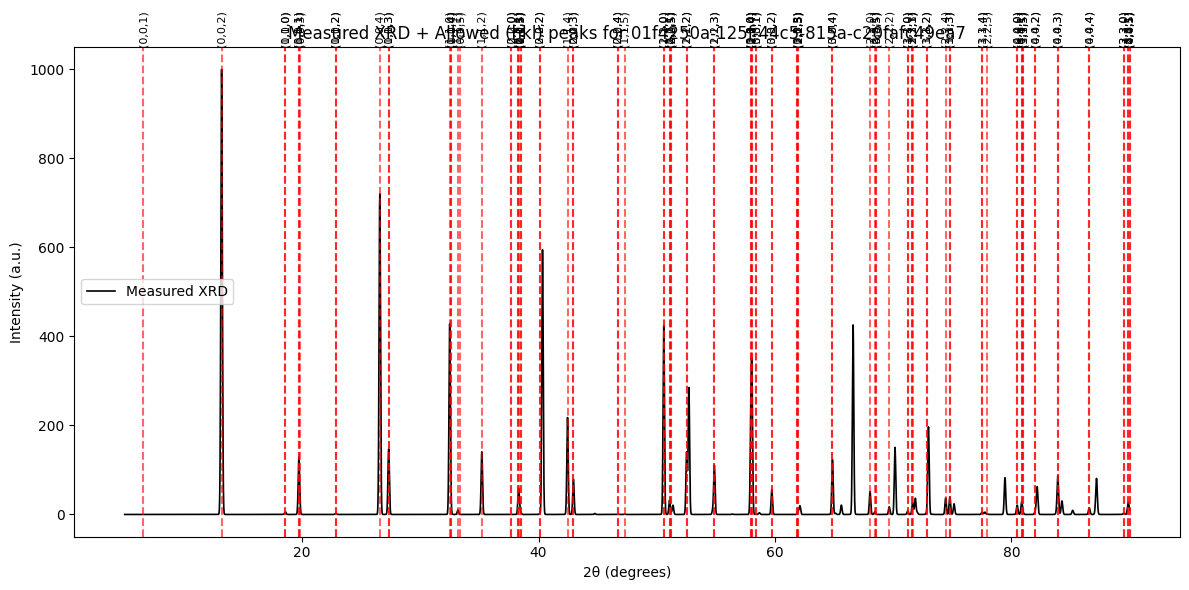

In [ ]:
plot_xrd_measured_with_hkls_lattice(
    hdf5_path=file_path_RRUFF_interp,
    db_path=file_path_db,
    pattern_index=0,
    wavelength=1.541838,
    twotheta_min=5,
    twotheta_max=90,
    max_hkl_index=5
)


In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pymatgen.core import Lattice
from scipy.signal import find_peaks

def plot_xrd_measured_with_top_hkls(hdf5_path, db_path, pattern_index,
                                    wavelength=1.541838,
                                    twotheta_min=5, twotheta_max=90,
                                    max_hkl_index=3,
                                    top_n_peaks=5,
                                    annotate_offset=0.05):
    """
    Plot measured XRD and overlay top N measured peaks with nearest allowed (hkl)
    using lattice parameters from SQLite DB.
    """
    # --- 1) Load measured pattern ---
    with h5py.File(hdf5_path, "r") as f:
        two_theta_full = f["2theta"][:]
        intensity_full = f["intensity"][:]
        mask = (two_theta_full >= twotheta_min) & (two_theta_full <= twotheta_max)
        two_theta = two_theta_full[mask]
        intensity = intensity_full[pattern_index, mask]

        if "structure_id" in f:
            structure_id = f["structure_id"][pattern_index]
            if isinstance(structure_id, bytes):
                structure_id = structure_id.decode("utf-8")
        else:
            structure_id = pattern_index

    # --- 2) Get lattice parameters from SQLite DB ---
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()
    cursor.execute("""
        SELECT lattice_a, lattice_b, lattice_c, alpha, beta, gamma
        FROM Structures
        WHERE structure_id = ?
    """, (structure_id,))
    result = cursor.fetchone()
    conn.close()
    if result is None:
        raise ValueError(f"No lattice found for structure_id={structure_id}")

    lattice_a, lattice_b, lattice_c, alpha, beta, gamma = result

    # --- 3) Create pymatgen lattice ---
    lattice = Lattice.from_parameters(lattice_a, lattice_b, lattice_c,
                                      alpha, beta, gamma)

    # --- 4) Generate allowed hkls ---
    allowed_hkls = []
    for h in range(max_hkl_index + 1):
        for k in range(max_hkl_index + 1):
            for l in range(max_hkl_index + 1):
                if h == k == l == 0:
                    continue
                allowed_hkls.append((h, k, l))

    # --- 5) Compute allowed 2θ positions ---
    allowed_two_theta = []
    valid_hkls = []
    for hkl in allowed_hkls:
        try:
            d = lattice.d_hkl(hkl)
        except ZeroDivisionError:
            continue
        sin_theta = wavelength / (2 * d)
        if sin_theta <= 1:
            theta = np.arcsin(sin_theta)
            two_theta_val = np.degrees(2 * theta)
            if twotheta_min <= two_theta_val <= twotheta_max:
                allowed_two_theta.append(two_theta_val)
                valid_hkls.append(hkl)
    allowed_two_theta = np.array(allowed_two_theta)
    valid_hkls = np.array(valid_hkls)

    # --- 6) Find top measured peaks ---
    peak_indices, _ = find_peaks(intensity)
    peak_intensities = intensity[peak_indices]
    if len(peak_indices) == 0:
        print("No peaks found!")
        return

    # Pick top N peaks
    top_idx = np.argsort(peak_intensities)[-top_n_peaks:][::-1]
    top_peaks = peak_indices[top_idx]
    top_two_theta = two_theta[top_peaks]
    top_intensity = intensity[top_peaks]

    # --- 7) Match nearest allowed hkl for each top peak ---
    top_hkls = []
    for tt in top_two_theta:
        if len(allowed_two_theta) == 0:
            top_hkls.append((0,0,0))
            continue
        idx = np.argmin(np.abs(allowed_two_theta - tt))
        top_hkls.append(valid_hkls[idx])

    # --- 8) Plot ---
    plt.figure(figsize=(12, 6))
    plt.plot(two_theta, intensity, color='black', lw=1.2, label='Measured XRD')

    for i in range(len(top_two_theta)):
        plt.text(top_two_theta[i], top_intensity[i] * (1 + annotate_offset),
                 f"({','.join(map(str, top_hkls[i]))})",
                 rotation=0, ha='center', va='bottom', fontsize=10, color='red')

    plt.xlabel("2θ (degrees)")
    plt.ylabel("Intensity (a.u.)")
    plt.title(f"Measured XRD + Top {top_n_peaks} (hkl) Peaks for {structure_id}")
    plt.legend()
    plt.tight_layout()
    plt.show()


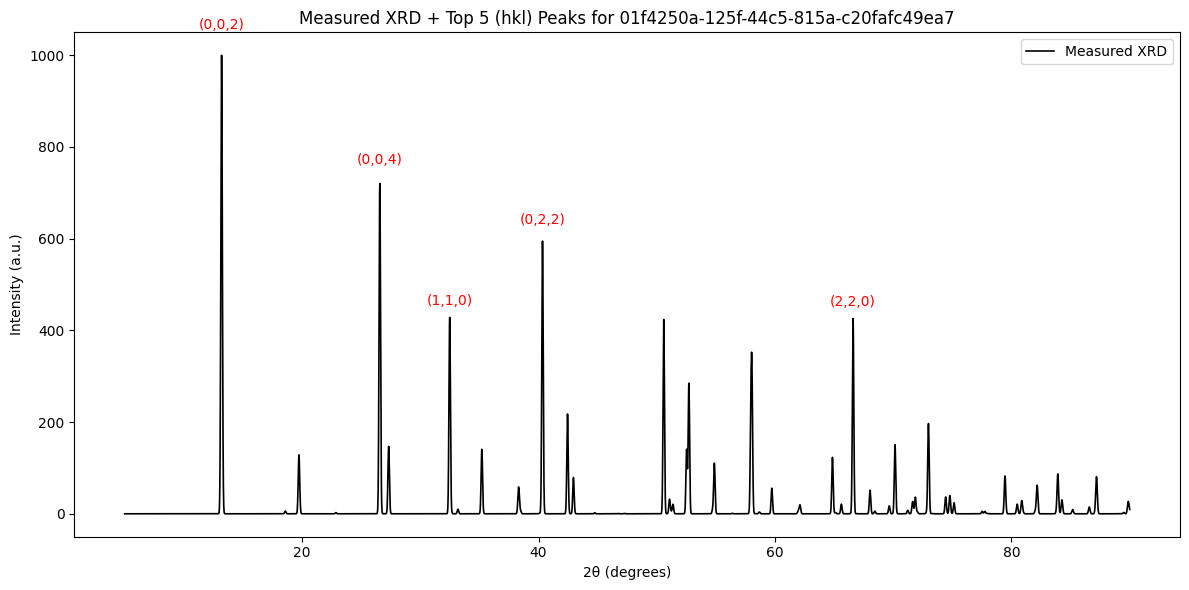

In [ ]:
plot_xrd_measured_with_top_hkls(
    hdf5_path=file_path_RRUFF_interp,
    db_path=file_path_db,
    pattern_index=0,
    wavelength=1.541838,
    twotheta_min=5,
    twotheta_max=90,
    max_hkl_index=5
)